# 07 - Transformando as features numericas

Esta etapa le `csvs/06_dataset_refinado.csv` e transforma as features numericas: coloca todas na mesma escala e reduz a assimetria das que tem cauda longa. O arquivo de entrada nao e alterado; o resultado sai em `csvs/07_dataset_transformado.csv`, com as mesmas linhas e colunas.

- **Para quem:** modelos lineares, de distancia (KNN, SVM) e redes neurais. Arvores e boosting sao indiferentes a transformacoes monotonas; para eles o arquivo 06 serve igual.
- **Sem vazamento:** todos os parametros (medias, desvios, lambdas, percentis) sao aprendidos so nas linhas de treino (`dataset_split == 'train'`, 2003-2024) e depois aplicados a validacao (2025) e ao teste (2026).
- **Nulos continuam nulos:** os `NaN` tem significado (estreia do piloto, sessao nao disputada) e a imputacao e outra etapa.
- **Ordem preservada:** todas as transformacoes sao monotonas crescentes; quem tinha valor maior continua com valor maior.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import BaseEstimator, OneToOneFeatureMixin, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, PowerTransformer, StandardScaler
from sklearn.utils.validation import check_is_fitted, validate_data

ENTRADA = 'csvs/06_dataset_refinado.csv'
SAIDA = 'csvs/07_dataset_transformado.csv'
ALVO = 'rd_position_display_order'

df = pd.read_csv(ENTRADA, low_memory=False)
treino = df['dataset_split'].eq('train')
print(f'Linhas: {len(df):,} | Colunas: {df.shape[1]} | Treino: {treino.sum():,} | Validacao + teste: {(~treino).sum():,}')

Linhas: 8,462 | Colunas: 51 | Treino: 7,966 | Validacao + teste: 496


## 1. Colunas numericas

Nem toda coluna numerica e feature a transformar:

| Coluna(s) | Decisao |
|---|---|
| `rd_position_display_order` | Alvo: fica como esta. |
| `race_id`, `race_year` | Metadados (group do ranking e divisao temporal, secoes 7 e 10 do `06_Refining_Dataset.ipynb`): ficam como estao. |
| `largou_do_pit_lane`, `sem_tempo_na_classificacao` | Flags 0/1: ja estao numa escala pronta. |
| Demais numericas | Features a transformar. |

O perfil abaixo e calculado so no treino e guia a escolha da secao 2.

In [2]:
METADADOS = ['race_id', 'race_year']
BINARIAS = ['largou_do_pit_lane', 'sem_tempo_na_classificacao']

numericas = df.select_dtypes('number').columns
FEATURES = [coluna for coluna in numericas if coluna not in [ALVO] + METADADOS + BINARIAS]
assert df[BINARIAS].isin([0, 1]).all().all()
print(f'Numericas: {len(numericas)} | Fora da transformacao: {len(numericas) - len(FEATURES)} | Features: {len(FEATURES)}')

X_treino = df.loc[treino, FEATURES]
perfil = pd.DataFrame({
    'nulos_pct': X_treino.isna().mean().mul(100),
    'zeros_pct': X_treino.eq(0).mean().mul(100),
    'min': X_treino.min(),
    'mediana': X_treino.median(),
    'max': X_treino.max(),
    'assimetria': X_treino.skew(),
    'curtose': X_treino.kurt(),
}).round(2).sort_values('assimetria', ascending=False)
display(perfil)

Numericas: 43 | Fora da transformacao: 5 | Features: 38


,nulos_pct,zeros_pct,min,mediana,max,assimetria,curtose
fp1_gap_pct,9.79,4.75,0.00,0.02,0.67,7.76,145.53
quali_gap_pct,1.76,4.77,0.00,0.02,0.47,5.40,42.14
driver_circuit_prior_wins,0.00,87.37,0.00,0.00,7.00,4.61,27.24
fp3_gap_pct,5.45,4.62,0.00,0.02,0.32,4.04,39.10
driver_circuit_prior_win_rate,28.33,59.04,0.00,0.00,1.00,3.84,17.36
driver_prior_wins,0.00,57.43,0.00,0.00,95.00,3.67,16.14
fp2_gap_pct,3.43,4.69,0.00,0.02,0.34,2.79,27.61
driver_prior_standing_points,0.00,27.63,0.00,11.00,549.00,2.62,8.00
driver_prior_win_rate,1.42,56.01,0.00,0.00,1.00,2.55,7.93
driver_prior_podiums,0.00,38.92,0.00,2.00,184.00,2.55,7.21


## 2. Escolha das transformacoes

As colunas caem em sete grupos. Todos terminam padronizados (media 0 e desvio 1 no treino); o que muda e o passo antes da padronizacao.

| Grupo | Colunas | Transformacao | Por que |
|---|---|---|---|
| Posicoes | `sess_grid_position_number`, `sess_fp1_position_number`, `sess_fp2_position_number`, `sess_fp3_position_number`, `sess_quali_position_number`, `driver_prior_standing_position`, `constructor_prior_standing_position` | Padronizacao | Distribuicao quase uniforme (assimetria perto de 0): log ou potencia so criariam assimetria no outro sentido. |
| Simetricas | `race_round`, `race_course_length`, `race_turns`, `race_grid_size`, `driver_age_years`, `driver_prior_avg_finish_last5`, `constructor_prior_avg_finish`, `engmfr_prior_avg_finish_last5` | Padronizacao | Assimetria abaixo de 1: basta trazer para a mesma escala. |
| Contagens e pontos | `driver_prior_entries`, `driver_prior_wins`, `driver_prior_podiums`, `driver_circuit_prior_entries`, `driver_circuit_prior_wins`, `constructor_prior_races`, `constructor_prior_wins`, `constructor_prior_poles`, `constructor_prior_podiums`, `driver_prior_standing_points`, `constructor_prior_standing_points`, `driver_prior_avg_points_last5`, `constructor_prior_avg_points_last5` | `log1p` + padronizacao | Cauda longa a direita e muitos zeros. O log comprime a cauda e traduz retorno decrescente: passar de 0 para 10 vitorias diz mais que passar de 80 para 90. |
| Gaps de tempo | `fp1_gap_pct`, `fp2_gap_pct`, `fp3_gap_pct`, `quali_gap_pct` | `log1p(100 * gap)` + padronizacao | Assimetria de 2,8 a 7,8: mediana perto de 2%, maximo de 67%. O gap vira pontos percentuais antes do log, porque em fracao (0,02) o `log1p` e quase linear e corrige pouco. |
| Taxas de abandono | `driver_prior_dnf_rate`, `constructor_prior_dnf_rate` | Yeo-Johnson (lambda aprendido no treino; ja padroniza) | Limitadas a [0, 1], com cauda a direita. |
| Taxas de vitoria | `driver_prior_win_rate`, `constructor_prior_win_rate`, `driver_circuit_prior_win_rate` | Raiz quadrada + padronizacao | Limitadas a [0, 1], com muitos zeros e cauda a direita. |
| Amostra pequena | `driver_prior_positions_gained_avg` | Winsorizacao nos percentis 1 e 99 do treino + padronizacao | Tem negativos (sem log) e os extremos vem de pilotos com poucas corridas. |

In [3]:
POSICOES = [
    'sess_grid_position_number', 'sess_fp1_position_number', 'sess_fp2_position_number',
    'sess_fp3_position_number', 'sess_quali_position_number',
    'driver_prior_standing_position', 'constructor_prior_standing_position',
]
SIMETRICAS = [
    'race_round', 'race_course_length', 'race_turns', 'race_grid_size', 'driver_age_years',
    'driver_prior_avg_finish_last5', 'constructor_prior_avg_finish', 'engmfr_prior_avg_finish_last5',
]
CONTAGENS = [
    'driver_prior_entries', 'driver_prior_wins', 'driver_prior_podiums',
    'driver_circuit_prior_entries', 'driver_circuit_prior_wins',
    'constructor_prior_races', 'constructor_prior_wins', 'constructor_prior_poles', 'constructor_prior_podiums',
    'driver_prior_standing_points', 'constructor_prior_standing_points',
    'driver_prior_avg_points_last5', 'constructor_prior_avg_points_last5',
]
GAPS = ['fp1_gap_pct', 'fp2_gap_pct', 'fp3_gap_pct', 'quali_gap_pct']
TAXAS_ABANDONO = ['driver_prior_dnf_rate', 'constructor_prior_dnf_rate']
TAXAS_VITORIA = ['driver_prior_win_rate', 'constructor_prior_win_rate', 'driver_circuit_prior_win_rate']
AMOSTRA_PEQUENA = ['driver_prior_positions_gained_avg']

GRUPOS = {
    'posicoes': POSICOES, 'simetricas': SIMETRICAS, 'contagens': CONTAGENS, 'gaps': GAPS,
    'taxas_abandono': TAXAS_ABANDONO, 'taxas_vitoria': TAXAS_VITORIA, 'amostra_pequena': AMOSTRA_PEQUENA,
}
TRANSFORMACAO = {
    'posicoes': 'padronizacao', 'simetricas': 'padronizacao', 'contagens': 'log1p + padronizacao',
    'gaps': 'log1p(100 * gap) + padronizacao', 'taxas_abandono': 'yeo-johnson',
    'taxas_vitoria': 'raiz quadrada + padronizacao', 'amostra_pequena': 'winsorizacao p1-p99 + padronizacao',
}
GRUPO_DA_COLUNA = {coluna: grupo for grupo, colunas in GRUPOS.items() for coluna in colunas}

# cada feature em exatamente um grupo
assert sum(len(colunas) for colunas in GRUPOS.values()) == len(GRUPO_DA_COLUNA) == len(FEATURES)
assert set(GRUPO_DA_COLUNA) == set(FEATURES)
# log1p e raiz exigem valores >= 0 em todas as linhas, inclusive validacao e teste
assert (df[CONTAGENS + GAPS + TAXAS_VITORIA].dropna() >= 0).all().all()

display(pd.Series({grupo: len(colunas) for grupo, colunas in GRUPOS.items()}, name='colunas').to_frame())

,colunas
posicoes,7
simetricas,8
contagens,13
gaps,4
taxas_abandono,2
taxas_vitoria,3
amostra_pequena,1


### Alternativas testadas

Nas posicoes, nas simetricas e nas contagens a escolha e direta (o efeito aparece na secao 4). Nos outros quatro grupos havia mais de um candidato razoavel. A tabela compara, no treino:

- `assimetria` e `curtose`;
- `pearson_alvo`: a relacao linear com o alvo, que e o que um modelo linear enxerga (Spearman fica de fora: transformacoes monotonas praticamente nao o alteram);
- `p90_ao_max`: quantos desvios padrao separam o percentil 90 do maximo depois da transformacao. Perto de zero quer dizer que a transformacao **satura**: os 10% maiores valores viram praticamente o mesmo numero.

Decisoes:

- **Gaps:** `log1p(100 * gap)` e Yeo-Johnson chegam a assimetria e correlacao parecidas, mas o Yeo-Johnson precisa de lambda perto de -30 e satura o topo. O log nao tem parametro e se le como "log de 1 + gap em %". Com o gap em fracao, o `log1p` corrige pouco.
- **Taxas de abandono:** Yeo-Johnson (lambda perto de -2,6, sem saturar) tira a assimetria e perde menos correlacao que a raiz quadrada.
- **Taxas de vitoria:** aqui o Yeo-Johnson precisa de lambda entre -7 e -20 e satura: acima de uns 20% de vitorias todos ficam com quase o mesmo valor, justamente onde estao os pilotos e equipes dominantes. A raiz quadrada da a mesma correlacao com o alvo e mantem o topo separado, ao custo de ficar com mais assimetria.
- **Amostra pequena:** Yeo-Johnson tira a assimetria, mas aumenta a curtose e reduz a correlacao. Cortar nos percentis 1 e 99 quase nao mexe na assimetria, mas derruba a curtose e aumenta a correlacao.

In [4]:
def log1p_percentual(x):
    # gap em fracao -> pontos percentuais antes do log
    return np.log1p(100 * x)


def yeo_johnson(serie):
    return pd.Series(PowerTransformer().fit_transform(serie.to_frame()).ravel(), index=serie.index)


ALTERNATIVAS = {
    'bruto': lambda serie: serie,
    'log1p': np.log1p,
    'log1p(100 * x)': log1p_percentual,
    'raiz quadrada': np.sqrt,
    'yeo-johnson': yeo_johnson,
    'winsorizacao p1-p99': lambda serie: serie.clip(*serie.quantile([0.01, 0.99])),
}
TESTES = [
    (GAPS, ['bruto', 'log1p', 'log1p(100 * x)', 'yeo-johnson'], 'log1p(100 * x)'),
    (TAXAS_ABANDONO, ['bruto', 'raiz quadrada', 'yeo-johnson'], 'yeo-johnson'),
    (TAXAS_VITORIA, ['bruto', 'raiz quadrada', 'yeo-johnson'], 'raiz quadrada'),
    (AMOSTRA_PEQUENA, ['bruto', 'yeo-johnson', 'winsorizacao p1-p99'], 'winsorizacao p1-p99'),
]

alvo_treino = df.loc[treino, ALVO]
linhas = []
for colunas, alternativas, escolhida in TESTES:
    for coluna in colunas:
        serie = X_treino[coluna].dropna()
        for nome in alternativas:
            transformada = ALTERNATIVAS[nome](serie)
            padronizada = (transformada - transformada.mean()) / transformada.std()
            linhas.append({
                'coluna': coluna,
                'alternativa': nome,
                'escolhida': 'sim' if nome == escolhida else '',
                'assimetria': transformada.skew(),
                'curtose': transformada.kurt(),
                'pearson_alvo': transformada.corr(alvo_treino.loc[serie.index]),
                'p90_ao_max': padronizada.max() - padronizada.quantile(0.9),
                'lambda': PowerTransformer().fit(serie.to_frame()).lambdas_[0] if nome == 'yeo-johnson' else np.nan,
            })
alternativas = pd.DataFrame(linhas).set_index(['coluna', 'alternativa']).round(2)
display(alternativas.fillna({'lambda': ''}))

ganho = X_treino['driver_prior_positions_gained_avg']
p1, p99 = ganho.quantile([0.01, 0.99])
extremos = ganho.notna() & ~ganho.between(p1, p99)
corridas_extremos = X_treino.loc[extremos, 'driver_prior_entries'].median()
print(f'driver_prior_positions_gained_avg fora de [{p1:.2f}, {p99:.2f}]: {extremos.sum()} linhas, '
      f'mediana de {corridas_extremos:.0f} corridas anteriores do piloto')

escolhida  assimetria  \
coluna                            alternativa                                 
fp1_gap_pct                       bruto                                7.76   
                                  log1p                                5.59   
                                  log1p(100 * x)            sim        0.20   
                                  yeo-johnson                          0.14   
fp2_gap_pct                       bruto                                2.79   
                                  log1p                                2.38   
                                  log1p(100 * x)            sim        0.08   
                                  yeo-johnson                          0.11   
fp3_gap_pct                       bruto                                4.04   
                                  log1p                                3.48   
                                  log1p(100 * x)            sim        0.28   
                                  yeo-johnson                          0.15   
quali_gap_pct                     bruto                                5.40   
                                  log1p                                4.79   
                                  log1p(100 * x)            sim        0.64   
                                  yeo-johnson                          0.27   
driver_prior_dnf_rate             bruto                                2.01   
                                  raiz quadrada                       -0.38   
                                  yeo-johnson               sim       -0.06   
constructor_prior_dnf_rate        bruto                                1.61   
                                  raiz quadrada                       -0.21   
                                  yeo-johnson               sim       -0.05   
driver_prior_win_rate             bruto                                2.55   
                                  raiz quadrada             sim        1.24   
                                  yeo-johnson                          0.87   
constructor_prior_win_rate        bruto                                1.54   
                                  raiz quadrada             sim        0.62   
                                  yeo-johnson                          0.53   
driver_circuit_prior_win_rate     bruto                                3.84   
                                  raiz quadrada             sim        2.26   
                                  yeo-johnson                          1.71   
driver_prior_positions_gained_avg bruto                                1.11   
                                  yeo-johnson                          0.16   
                                  winsorizacao p1-p99       sim        1.05   

                                                       curtose  pearson_alvo  \
coluna                            alternativa                                  
fp1_gap_pct                       bruto                 145.53          0.33   
                                  log1p                  78.95          0.35   
                                  log1p(100 * x)          0.51          0.47   
                                  yeo-johnson            -0.49          0.48   
fp2_gap_pct                       bruto                  27.61          0.45   
                                  log1p                  18.64          0.46   
                                  log1p(100 * x)         -0.16          0.51   
                                  yeo-johnson            -0.61          0.51   
fp3_gap_pct                       bruto                  39.10          0.39   
                                  log1p                  28.76          0.40   
                                  log1p(100 * x)          0.31          0.49   
                                  yeo-johnson            -0.54          0.50   
quali_gap_pct                     bruto                  42.14          0.26   
         

driver_prior_positions_gained_avg fora de [-1.00, 6.57]: 156 linhas, mediana de 4 corridas anteriores do piloto


## 3. Ajuste no treino e aplicacao

Um unico `ColumnTransformer` junta os sete grupos. Ele e ajustado so com as linhas de treino e depois aplicado a todas as linhas. Na validacao e no teste a media e o desvio nao saem exatamente 0 e 1: e o esperado quando os parametros vem so do treino.

O scikit-learn nao tem winsorizacao pronta. `Winsorizar` guarda os percentis no `fit` e so corta no `transform`, para que os limites tambem venham do treino.

In [5]:
class Winsorizar(OneToOneFeatureMixin, TransformerMixin, BaseEstimator):
    # Corta cada coluna nos percentis aprendidos no fit; NaN continua NaN.

    def __init__(self, inferior=0.01, superior=0.99):
        self.inferior = inferior
        self.superior = superior

    def fit(self, X, y=None):
        X = validate_data(self, X, ensure_all_finite='allow-nan')
        self.limites_ = np.nanquantile(X, [self.inferior, self.superior], axis=0)
        return self

    def transform(self, X):
        check_is_fitted(self)
        X = validate_data(self, X, ensure_all_finite='allow-nan', reset=False)
        return np.clip(X, self.limites_[0], self.limites_[1])


transformador = ColumnTransformer(
    [
        ('padronizacao', StandardScaler(), POSICOES + SIMETRICAS),
        ('contagens', make_pipeline(
            FunctionTransformer(np.log1p, feature_names_out='one-to-one'), StandardScaler(),
        ), CONTAGENS),
        ('gaps', make_pipeline(
            FunctionTransformer(log1p_percentual, feature_names_out='one-to-one'), StandardScaler(),
        ), GAPS),
        ('taxas_abandono', PowerTransformer(method='yeo-johnson', standardize=True), TAXAS_ABANDONO),
        ('taxas_vitoria', make_pipeline(
            FunctionTransformer(np.sqrt, feature_names_out='one-to-one'), StandardScaler(),
        ), TAXAS_VITORIA),
        ('amostra_pequena', make_pipeline(Winsorizar(0.01, 0.99), StandardScaler()), AMOSTRA_PEQUENA),
    ],
    verbose_feature_names_out=False,
).set_output(transform='pandas')

transformador.fit(df.loc[treino, FEATURES])
transformadas = transformador.transform(df[FEATURES])

df_transformado = df.copy()
df_transformado[FEATURES] = transformadas[FEATURES]

lambdas = transformador.named_transformers_['taxas_abandono'].lambdas_
limites = transformador.named_transformers_['amostra_pequena'][0].limites_.ravel()
print('Lambdas Yeo-Johnson aprendidos no treino:')
for coluna, valor in zip(TAXAS_ABANDONO, lambdas):
    print(f'  {coluna}: {valor:.2f}')
print(f'Limites da winsorizacao (treino): [{limites[0]:.2f}, {limites[1]:.2f}]')

Lambdas Yeo-Johnson aprendidos no treino:
  driver_prior_dnf_rate: -2.58
  constructor_prior_dnf_rate: -2.72
Limites da winsorizacao (treino): [-1.00, 6.57]


## 4. Conferencias

- Linhas, colunas e tudo o que nao e feature (alvo, metadados, flags, categoricas) continuam identicos ao arquivo 06.
- Os nulos ficam exatamente nas mesmas celulas.
- No treino, toda feature tem media 0 e desvio 1.
- Nenhuma transformacao inverte a ordem: ordenando pelo valor original, o valor transformado nunca diminui.

Na tabela, algumas features continuam com assimetria acima de 1, e isso e esperado:

- `driver_prior_wins`, `driver_prior_win_rate`, `driver_circuit_prior_wins` e `driver_circuit_prior_win_rate` tem mais da metade das linhas em zero, e uma transformacao monotona nao separa valores iguais.
- Em `driver_prior_positions_gained_avg` a winsorizacao mira a cauda, nao a assimetria.

Em `driver_prior_entries` e `constructor_prior_races` o log passa um pouco do ponto (assimetria perto de -0,8), mas o retorno decrescente da experiencia vale igual e a correlacao com o alvo nao piora.

In [6]:
assert df_transformado.shape == df.shape
assert list(df_transformado.columns) == list(df.columns)
assert df_transformado.drop(columns=FEATURES).equals(df.drop(columns=FEATURES))
assert df_transformado[FEATURES].isna().equals(df[FEATURES].isna())

depois_treino = df_transformado.loc[treino, FEATURES]
assert np.allclose(depois_treino.mean(), 0, atol=1e-6)
assert np.allclose(depois_treino.std(ddof=0), 1, atol=1e-6)

for coluna in FEATURES:
    par = pd.DataFrame({'antes': df[coluna], 'depois': df_transformado[coluna]}).dropna()
    par = par.sort_values('antes', kind='mergesort')
    assert par['depois'].diff().dropna().ge(-1e-9).all(), coluna

comparacao = pd.DataFrame({
    'transformacao': pd.Series(GRUPO_DA_COLUNA).map(TRANSFORMACAO),
    'assimetria_antes': X_treino.skew(),
    'assimetria_depois': depois_treino.skew(),
    'pearson_alvo_antes': X_treino.corrwith(alvo_treino),
    'pearson_alvo_depois': depois_treino.corrwith(alvo_treino),
}).loc[FEATURES].round(2)
display(comparacao)

assimetricas_antes = comparacao['assimetria_antes'].abs().gt(1).sum()
assimetricas_depois = comparacao['assimetria_depois'].abs().gt(1).sum()
print(f'Features com |assimetria| > 1 no treino: {assimetricas_antes} -> {assimetricas_depois}')

,transformacao,assimetria_antes,assimetria_depois,pearson_alvo_antes,pearson_alvo_depois
race_round,padronizacao,0.10,0.10,-0.01,-0.01
race_course_length,padronizacao,-0.05,-0.05,0.01,0.01
race_turns,padronizacao,0.50,0.50,0.01,0.01
sess_grid_position_number,padronizacao,0.07,0.07,0.61,0.61
sess_fp1_position_number,padronizacao,0.12,0.12,0.48,0.48
sess_fp2_position_number,padronizacao,0.13,0.13,0.53,0.53
sess_fp3_position_number,padronizacao,0.06,0.06,0.53,0.53
sess_quali_position_number,padronizacao,0.06,0.06,0.62,0.62
driver_prior_dnf_rate,yeo-johnson,2.01,-0.06,0.18,0.16
constructor_prior_dnf_rate,yeo-johnson,1.61,-0.05,0.27,0.27


Features com |assimetria| > 1 no treino: 22 -> 5


## 5. Distribuicoes antes e depois

Uma coluna de cada grupo, no treino. A escala do eixo x muda de um painel para o outro: a comparacao e a forma da distribuicao, nao os valores.

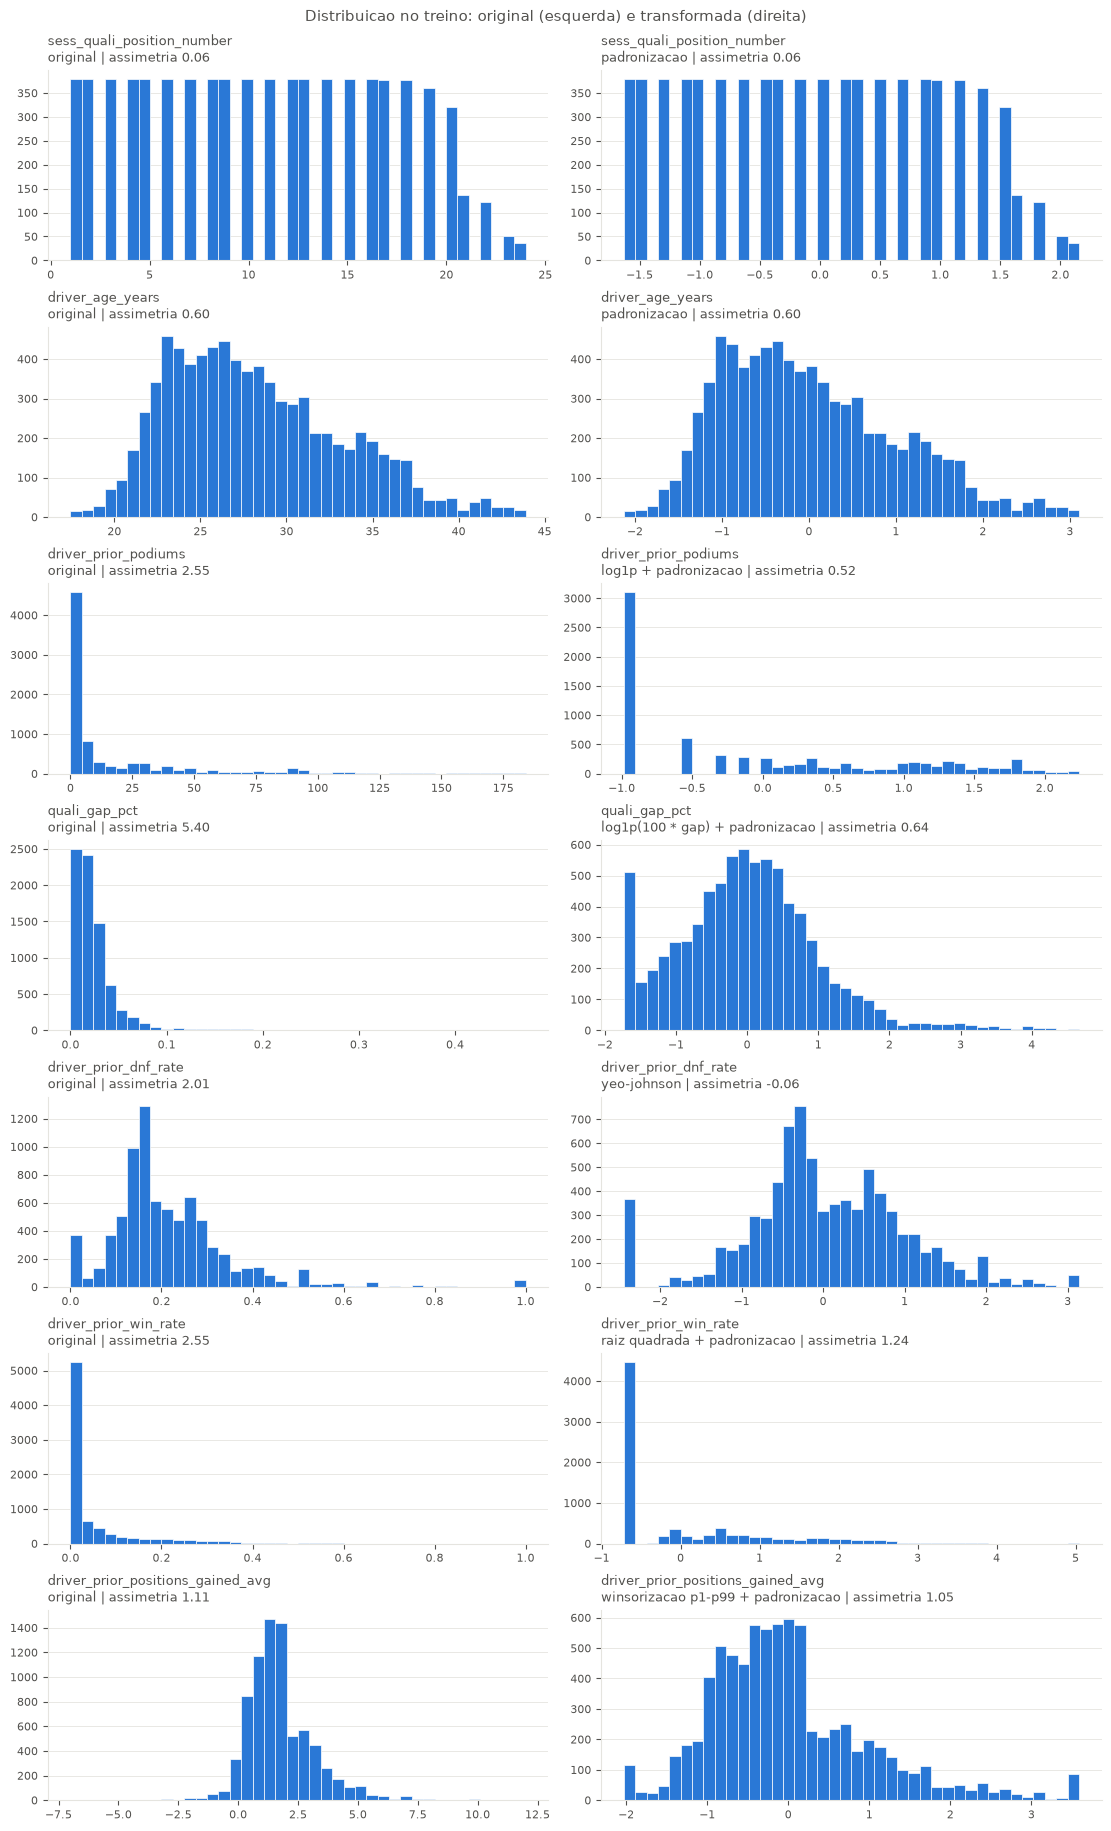

In [7]:
COR = '#2a78d6'
TINTA = '#52514e'
GRADE = '#e5e4df'
EXEMPLOS = [
    'sess_quali_position_number', 'driver_age_years', 'driver_prior_podiums',
    'quali_gap_pct', 'driver_prior_dnf_rate', 'driver_prior_win_rate', 'driver_prior_positions_gained_avg',
]

fig, eixos = plt.subplots(len(EXEMPLOS), 2, figsize=(11, 2.6 * len(EXEMPLOS)), layout='constrained')
for (eixo_antes, eixo_depois), coluna in zip(eixos, EXEMPLOS):
    for eixo, valores, rotulo in [
        (eixo_antes, X_treino[coluna], 'original'),
        (eixo_depois, depois_treino[coluna], TRANSFORMACAO[GRUPO_DA_COLUNA[coluna]]),
    ]:
        eixo.hist(valores.dropna(), bins=40, color=COR, edgecolor='white', linewidth=0.5)
        eixo.set_title(f'{coluna}\n{rotulo} | assimetria {valores.skew():.2f}', fontsize=9, color=TINTA, loc='left')
        eixo.spines[['top', 'right']].set_visible(False)
        eixo.spines[['left', 'bottom']].set_color(GRADE)
        eixo.tick_params(labelsize=8, colors=TINTA)
        eixo.grid(axis='y', color=GRADE, linewidth=0.6)
        eixo.set_axisbelow(True)
fig.suptitle('Distribuicao no treino: original (esquerda) e transformada (direita)', fontsize=11, color=TINTA)
plt.show()

## 6. Salvando

O CSV guarda os valores ja transformados com os parametros do treino inteiro. Isso serve para a divisao fixa treino / validacao / teste. Para validacao cruzada dentro do treino, use o `transformador` dentro de um `Pipeline` (reajustado a cada dobra) a partir do arquivo 06; usar este CSV ali vazaria as dobras de validacao para o ajuste.

In [8]:
df_transformado.to_csv(SAIDA, index=False)
print(f'Features transformadas: {len(FEATURES)} | Inalteradas: {df.shape[1] - len(FEATURES)}')
print(f'Linhas: {len(df_transformado):,} | Colunas: {df_transformado.shape[1]}')
print(f'Arquivo salvo: {SAIDA}')

Features transformadas: 38 | Inalteradas: 13
Linhas: 8,462 | Colunas: 51
Arquivo salvo: csvs/07_dataset_transformado.csv
